In [17]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import defaultdict

# Frases

Foi retirada uma série de frases do artigo "Development and Validation of an Affordable Wearable Multichannel EEG System With Active Electrodes and Innovative Flexible Headbands (Antolínez et al., 2025)", que serão utilizadas para formar as árvores de palavras.

In [18]:
frases = [
    "The growing interest in electroencephalography EEG research has highlighted the need for low-cost wearable EEG acquisition systems",
    "The high cost of commercially available EEG equipment poses a significant challenge to the widespread adoption of these systems",
    "This paper presents the design of a low-cost wearable 4-channel EEG acquisition system",
    "The solution is based on the ADS1299 a 24-bit analog front-end optimized for biomedical signal acquisition",
    "Active wet electrodes are employed each fitted with a preamplification board",
    "The electrodes are affixed to elastic bands using 3D-printed parts designed to facilitate rapid and straightforward electrode placement",
    "An additional reference electrode is placed in an ear-clip",
    "The headbands allow for the precise positioning of the electrodes at various strategic points on the scalp adhering to the 10-10 system",
    "To evaluate the viability of our design EEG signals from ten healthy subjects were registered and compared to commercial equipment",
    "Our design demonstrated signal quality comparable to reference EEG equipment while drastically reducing the cost and enhancing usability for practical applications",
    "The electroencephalography EEG is a widely used non-invasive technique for acquiring brain signals",
    "This approach involves placing multiple electrodes on the scalp to record the electrical potentials generated by neuronal activity",
    "EEG is commonly employed in the diagnosis of neurological disorders sleep studies cognitive workload assessment and neurophysiological research such as brain-computer interfacing BCI",
    "One of the primary challenges in EEG signal acquisition is minimizing noise effects",
    "Due to their low amplitudes and high source impedances EEG signals are highly susceptible to various forms of interference",
    "Addressing these challenges is essential to ensuring the accuracy and reliability of EEG-based analyses",
    "numerous research groups have emerged with a dedicated focus on EEG-based studies especially in the field of health sciences and rehabilitation",
    "recent developments have prioritized wearable and highly adaptable designs",
    "Commercially available EEG devices generally come with a high cost",
    "High-quality EEG devices often include CE and FDA certifications as medical devices",
    "these certifications are unnecessary for many EEG applications such as BCIs focused on communication device control or entertainment",
    "Limited availability of high-quality EEG equipment tailored for these applications leads researchers to rely on costly clinical-grade recording instruments",
    "costs can be reduced by optimizing the electrode number and strategically positioning EEG electrodes to focus on specific brain areas",
    "In EEG signal recording electrodes can be wet or dry",
    "Wet electrodes employ a conductive gel to reduce impedance between skin and electrode thereby minimizing external noise and motion artifacts",
    "there is a need for wearable EEG recording systems optimized for practical applications reducing the costs associated with an excess of channels and clinical certifications",
    "This study aims to address this gap by designing and developing a low-cost EEG signal acquisition system",
    "The proposed wearable device priced at 200 USD incorporates wireless BLE communication and features four active wet electrodes with 24-bit resolution",
    "The main novelty of our design lies in the integration of features typically absent in low-cost devices such as active wet electrodes and high-resolution ADCs",
    "the signal quality of the proposed system is assessed and benchmarked against the g.Nautilus PRO commercial system",
    "The main technical requirements and specifications for an EEG acquisition system intended for practical applications are described below",
    "Active wet electrodes to ensure good signal quality",
    "Common Mode Rejection Ratio CMRR of 95 dB or greater at preamplification to extract a high-quality EEG by rejecting the mains interference",
]

# Construção e Visualização da Árvore

A árvore de palavras é construída a partir da identificação de um termo central escolhido (raíz) nas frases analisadas. A partir de cada ocorrência desse termo, o algoritmo extrai as palavras seguintes, organizando-as em sequências com níveis de profundidade. A visualização da árvore é construída utilizando a biblioteca NetworkX para representar as sequências de palavras em forma de um grafo direcionado, no qual os nós representam as palavras e as arestas indicam suas conexões.

In [19]:
# Função para construir a árvore de palavras a partir de um termo central
def construir_arvore(frases, termo_central, max_profundidade = 5):
    termo = termo_central.lower()
    arvore = defaultdict(lambda: defaultdict(int))
    
    for frase in frases:
        palavras = frase.lower().split()
        if termo not in palavras:
            continue
        idx = palavras.index(termo)
        sequencia = palavras[idx + 1 : idx + 1 + max_profundidade]
        
        if not sequencia:
            continue
            
        # Conta os caminhos
        caminho = [termo]
        for palavra in sequencia:
            caminho.append(palavra)
            chave = tuple(caminho)
            arvore[chave[:-1]][chave[-1]] += 1
    
    return arvore

termo = "eeg" # Termo central escolhido
arvore = construir_arvore(frases, termo)

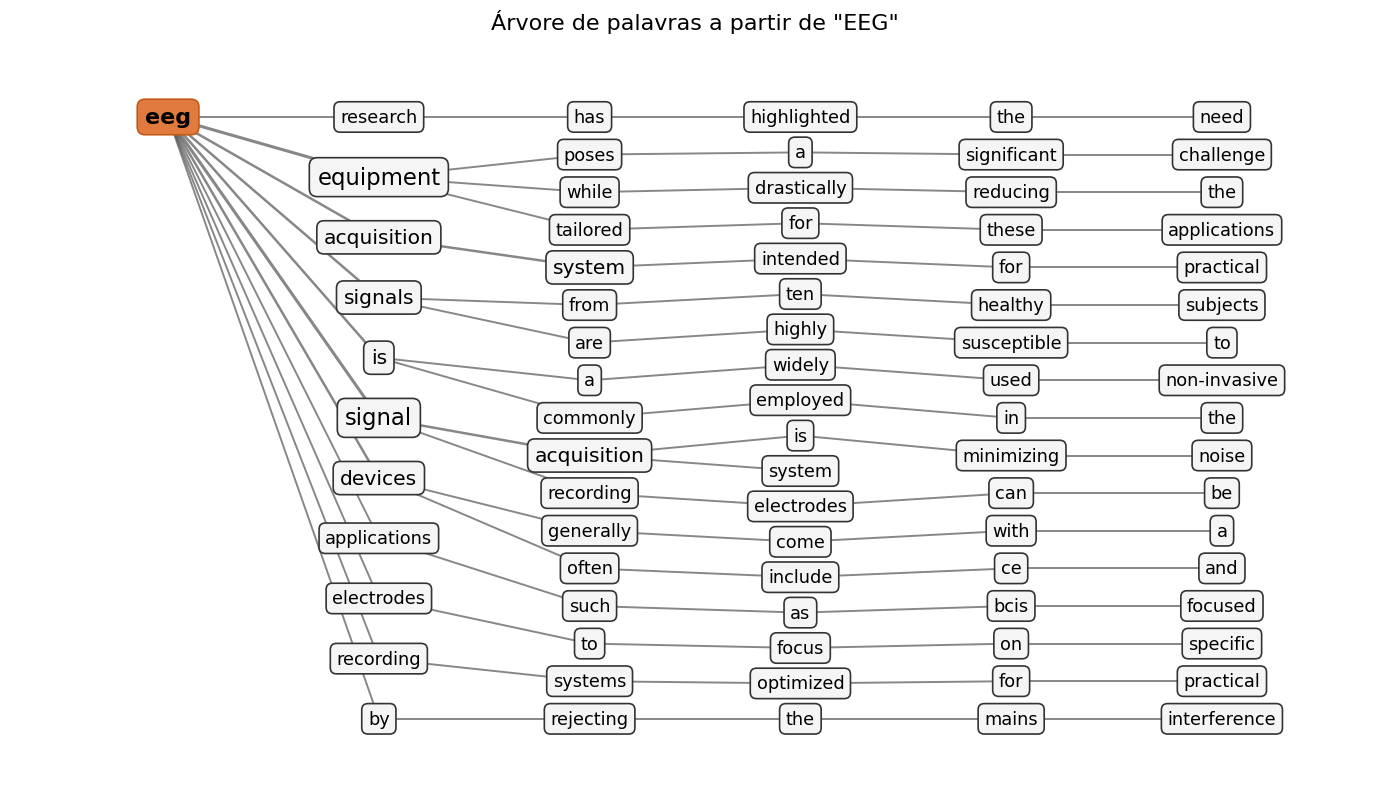

In [20]:
# Visualização da árvore
def plot_word_tree(arvore, termo_central, titulo="Árvore de palavras", id="01"):
    G = nx.DiGraph()
    
    # Adiciona nós e arestas com peso
    for caminho, filhos in arvore.items():
        pai = " ".join(caminho)
        for filho, freq in filhos.items():
            filho_label = " ".join(list(caminho) + [filho])
            G.add_edge(pai, filho_label, weight=freq)
            G.nodes[filho_label]["label"] = filho
            G.nodes[filho_label]["freq"] = freq
    
    # Garante o nó raiz
    if termo_central not in G.nodes:
        G.add_node(termo_central, label=termo_central, freq=10)
    
    # Layout hierárquico manual (esquerda -> direita)
    pos = {}
    niveis = defaultdict(list)
    
    # Calcula níveis
    for node in nx.topological_sort(G):
        if G.in_degree(node) == 0:
            niveis[0].append(node)
        else:
            pred = list(G.predecessors(node))[0]
            nivel = max([n for n, nodes in niveis.items() if pred in nodes], default = 0) + 1
            niveis[nivel].append(node)
    
    # Posiciona os nós
    max_nivel = max(niveis.keys()) if niveis else 0
    for nivel, nodes in niveis.items():
        y_positions = np.linspace(1, 0, len(nodes))
        for i, node in enumerate(nodes):
            pos[node] = (nivel / max(max_nivel, 1), y_positions[i])
    
    # Desenho
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Arestas
    for u, v, data in G.edges(data=True):
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        ax.plot([x1, x2], [y1, y2], color="#555555", linewidth = 1 + data["weight"] * 0.4, alpha = 0.7, zorder = 1)
    
    # Nós
    for node, (x, y) in pos.items():
        label = G.nodes[node].get("label", node.split()[-1])
        freq = G.nodes[node].get("freq", 1)
        
        fontsize = 11 + min(freq * 1.8, 10)
        
        bbox = dict(boxstyle = "round, pad = 0.35", facecolor = "#f5f5f5", edgecolor = "#333333", linewidth = 1.2)
        
        if node == termo_central or label == termo_central:
            bbox["facecolor"] = "#e07a3d" # Destaque laranja
            bbox["edgecolor"] = "#c45a1a"
            fontsize = 16
        
        ax.text(x, y, label, ha = "center", va = "center", fontsize = fontsize, fontweight = "bold" if label == termo_central else "normal", bbox = bbox, zorder = 2)
    
    ax.set_xlim(-0.15, 1.15)
    ax.set_ylim(-0.1, 1.1)
    ax.axis("off")
    ax.set_title(titulo, fontsize = 16, pad = 20, fontweight = "medium")
    
    plt.tight_layout()
    plt.savefig(f"figs/topico_07_04_{id}.png", dpi = 300)
    plt.show()

plot_word_tree(arvore, termo, titulo=f'Árvore de palavras a partir de "{termo.upper()}"', id="01")

# Profundidade da árvore

Também podemos mudar a profundidade da árvore, para este exemplo, diminuimos a profundidade padrão de 5 para 3.

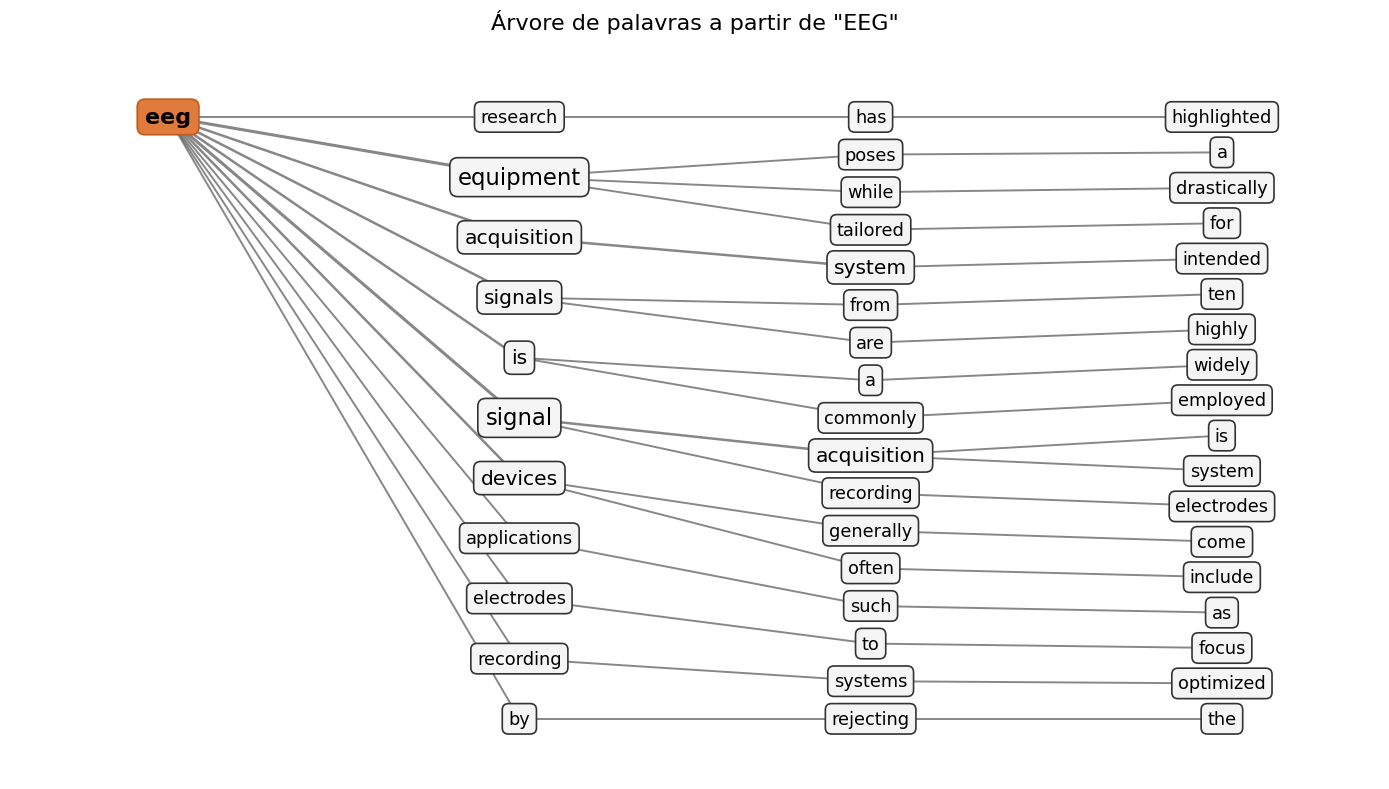

In [21]:
# Visualização da árvore
termo_2 = "eeg" # Termo central escolhido
arvore_2 = construir_arvore(frases, termo_2, 3) # Árvore com profundidade máxima de 3

plot_word_tree(arvore_2, termo_2, titulo=f'Árvore de palavras a partir de "{termo_2.upper()}"', id="02")

# Visualização da árvore a partir de outro termo

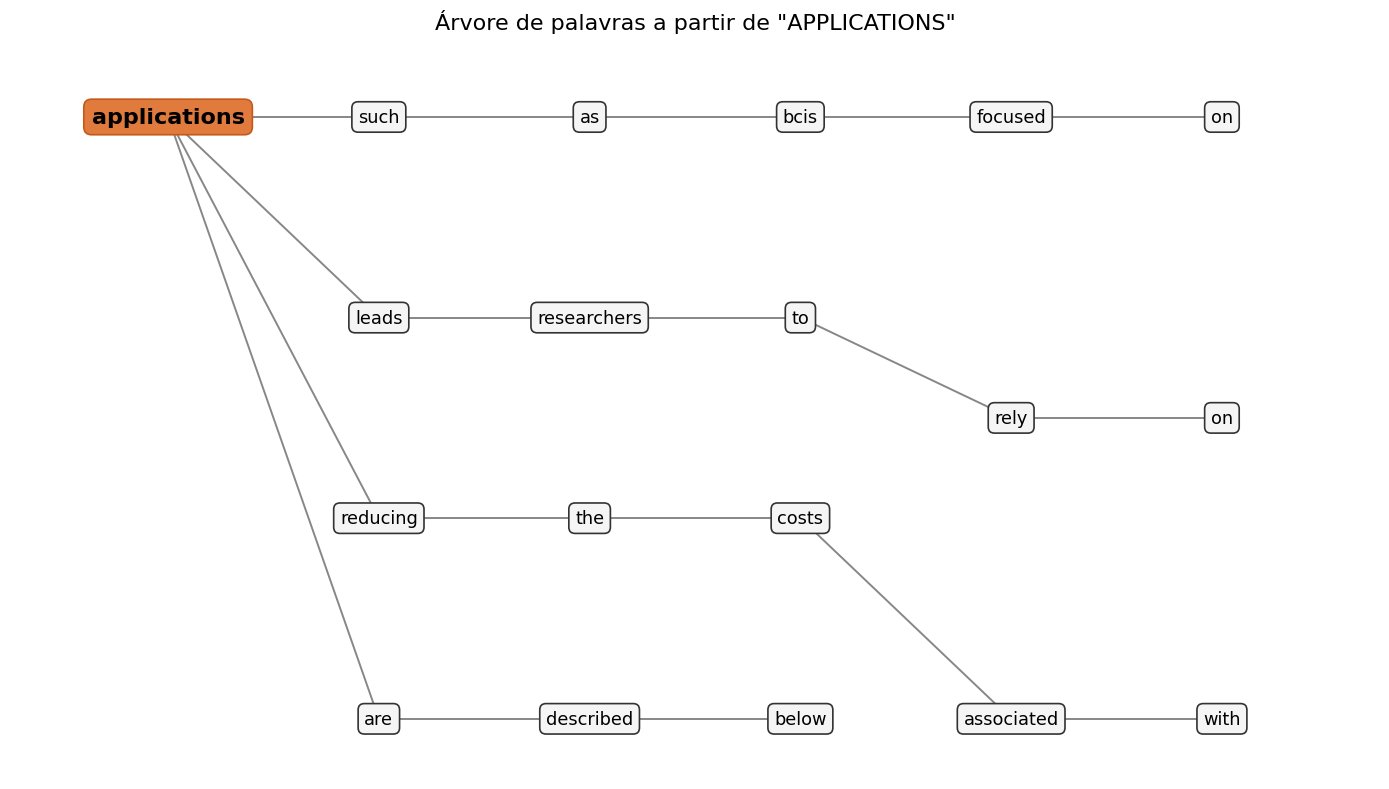

In [22]:
# Visualização da árvore
termo_3 = "applications" # Termo central escolhido
arvore_3 = construir_arvore(frases, termo_3) # Árvore com outro termo central

plot_word_tree(arvore_3, termo_3, titulo=f'Árvore de palavras a partir de "{termo_3.upper()}"', id="03")